<a href="https://colab.research.google.com/github/vitriadwiernita/TUGAS-ANMUL-KELOMPOK-3/blob/main/Kelompok3_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Library

In [ ]:
!pip install factor-analyzer

# Import library untuk pengolahan data
import pandas as pd
import numpy as np

# Import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library untuk analisis faktor
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (
    calculate_kmo,
    calculate_bartlett_sphericity
)

# Import library untuk PCA
from sklearn.decomposition import PCA

# Import library untuk preprocessing
from sklearn.preprocessing import MinMaxScaler

# Import library untuk clustering
from sklearn.cluster import AgglomerativeClustering

# Import library untuk dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage

# Mengatur tampilan grafik
sns.set(style="whitegrid")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor-analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=1877b596f081116d9f54a6e2afa7baa7a115512fc088dd038d2b0b5a4461088c
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor-analyzer


Bagian FA

Import Dataset

In [ ]:
# Membaca dataset customer
data = pd.read_csv("customer.csv")

# Menampilkan 5 observasi pertama
data.head()

# Menampilkan informasi struktur dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1175 entries, 0 to 1174
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  1175 non-null   int64
 1   age          1175 non-null   int64
 2   spending     1175 non-null   int64
dtypes: int64(3)
memory usage: 27.7 KB


Eksplorasi Data

In [ ]:
# Menampilkan statistik deskriptif
data.describe()

# Memeriksa missing value
data.isnull().sum()

# Memeriksa data duplikat
data.duplicated().sum()

np.int64(0)

Menghapus Variabel Id

In [ ]:
# Menghapus customer_id dari dataset
data_fa = data.drop(columns=["customer_id"])

# Menampilkan dataset yang digunakan dalam FA
data_fa.head()

,age,spending
0,51,4339
1,48,4700
2,10,1352
3,37,2457
4,42,1266


Matrix Korelaasi

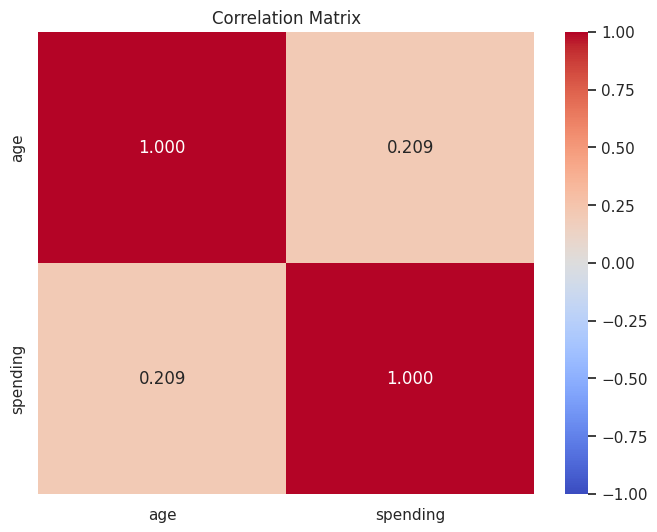

In [ ]:
# Menghitung matriks korelasi
correlation_matrix = data_fa.corr()

# Membuat visualisasi matriks korelasi
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f"
)

plt.title("Correlation Matrix")
plt.show()

KMO

In [ ]:
# Menghitung KMO dan MSA
kmo_all, kmo_model = calculate_kmo(data_fa)

# Menampilkan nilai KMO keseluruhan
print("KMO =", round(kmo_model, 4))

# Menampilkan nilai MSA masing-masing variabel
msa = pd.DataFrame({
    "Variabel": data_fa.columns,
    "MSA": kmo_all
})

display(msa)


KMO = 0.5


,Variabel,MSA
0,age,0.5
1,spending,0.5


Bartlett's Test of Sphericity

In [ ]:
# Melakukan Bartlett's Test
chi_square, p_value = calculate_bartlett_sphericity(data_fa)

# Menampilkan hasil pengujian
print("Chi-Square =", round(chi_square, 4))
print("P-value =", p_value)

# Menentukan keputusan
alpha = 0.05

if p_value < alpha:
    print("Keputusan: Tolak H0")
    print("Kesimpulan: Terdapat korelasi antarvariabel.")
else:
    print("Keputusan: Gagal menolak H0")
    print("Kesimpulan: Korelasi belum memadai.")

Chi-Square = 52.1875
P-value = 5.044712118669509e-13
Keputusan: Tolak H0
Kesimpulan: Terdapat korelasi antarvariabel.


Scree Plot

Eigenvalue:
[1.20864695 0.79135305]


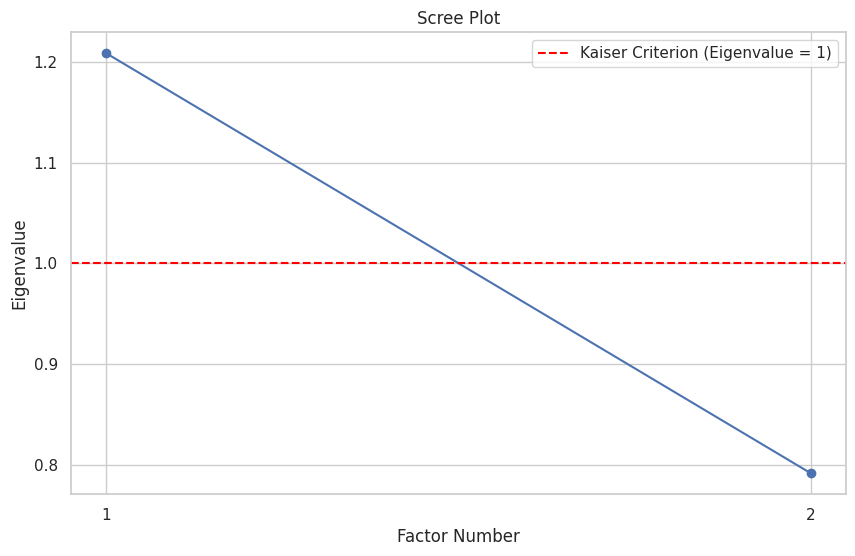

Jumlah faktor berdasarkan Kaiser Criterion: 1


In [ ]:
# Menghitung eigenvalue dan eigenvector
# berdasarkan matriks korelasi
eigenvalues, eigenvectors = np.linalg.eig(
    data_fa.corr()
)

# Mengurutkan eigenvalue dari terbesar ke terkecil
eigenvalues = np.sort(eigenvalues)[::-1]

# Menampilkan nilai eigenvalue
print("Eigenvalue:")
print(eigenvalues)

# Membuat Scree Plot
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker="o",
    linestyle="-"
)

# Menambahkan garis batas eigenvalue = 1
plt.axhline(
    y=1,
    color="red",
    linestyle="--",
    label="Kaiser Criterion (Eigenvalue = 1)"
)

# Memberikan judul dan label
plt.title("Scree Plot")
plt.xlabel("Factor Number")
plt.ylabel("Eigenvalue")

# Menampilkan nomor faktor pada sumbu X
plt.xticks(
    range(1, len(eigenvalues) + 1)
)

plt.legend()
plt.grid(True)

# Menampilkan grafik
plt.show()

# Menentukan faktor yang memiliki eigenvalue > 1
n_factors = sum(eigenvalues > 1)

# Menampilkan jumlah faktor yang dipertahankan
print("Jumlah faktor berdasarkan Kaiser Criterion:", n_factors)

PCA

In [ ]:

# Menentukan jumlah komponen
n_components = 2

# Membentuk model PCA menggunakan FactorAnalyzer
fa_pca = FactorAnalyzer(
    n_factors=n_components,
    method="principal",
    rotation="varimax"
)

# Melakukan fitting PCA
fa_pca.fit(data_fa)

# Menampilkan Factor Loading PCA
loading_pca = pd.DataFrame(
    fa_pca.loadings_,
    index=data_fa.columns,
    columns=["Factor 1", "Factor 2"]
)

print("Factor Loading PCA:")
display(loading_pca)

# Menampilkan Communality PCA
communality_pca = pd.DataFrame({
    "Variabel": data_fa.columns,
    "Communality": fa_pca.get_communalities()
})

print("Communality PCA:")
display(communality_pca)

# Menampilkan Variance Explained
variance_pca = pd.DataFrame(
    fa_pca.get_factor_variance(),
    index=["SS Loadings", "Proportion Variance",
           "Cumulative Variance"],
    columns=["Factor 1", "Factor 2"]
)

print("Variance Explained PCA:")
display(variance_pca)

Factor Loading PCA:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor 1,Factor 2
age,-0.603739,0.797182
spending,0.653669,0.756781


Communality PCA:


,Variabel,Communality
0,age,1.0
1,spending,1.0


Variance Explained PCA:


,Factor 1,Factor 2
SS Loadings,0.791783,1.208217
Proportion Variance,0.395892,0.604108
Cumulative Variance,0.395892,1.000000


PAF

In [ ]:


# Menentukan jumlah faktor
n_factors = 2

# Membentuk model PFA
fa_pfa = FactorAnalyzer(
    n_factors=n_factors,
    method="principal",
    rotation="varimax"
)

# Melakukan fitting PFA
fa_pfa.fit(data_fa)

# Menampilkan Factor Loading PFA
loading_pfa = pd.DataFrame(
    fa_pfa.loadings_,
    index=data_fa.columns,
    columns=["Factor 1", "Factor 2"]
)

print("Factor Loading PFA:")
display(loading_pfa)

# Menampilkan Communality
communality_pfa = pd.DataFrame({
    "Variabel": data_fa.columns,
    "Communality": fa_pfa.get_communalities()
})

print("Communality PFA:")
display(communality_pfa)

# Menampilkan Variance Explained
variance_pfa = pd.DataFrame(
    fa_pfa.get_factor_variance(),
    index=["SS Loadings", "Proportion Variance",
           "Cumulative Variance"],
    columns=["Factor 1", "Factor 2"]
)

print("Variance Explained PFA:")
display(variance_pfa)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Factor Loading PFA:


,Factor 1,Factor 2
age,-0.603739,0.797182
spending,0.653669,0.756781


Communality PFA:


,Variabel,Communality
0,age,1.0
1,spending,1.0


Variance Explained PFA:


,Factor 1,Factor 2
SS Loadings,0.791783,1.208217
Proportion Variance,0.395892,0.604108
Cumulative Variance,0.395892,1.000000


Communality

In [ ]:
# Menghitung nilai communality
communality = pd.DataFrame({
    "Variabel": data_fa.columns,
    "Communality": fa.get_communalities()
})

display(communality)

,Variabel,Communality
0,age,1.0
1,spending,1.0


Faktor Loading

In [ ]:

# Menghitung skor faktor dari model PFA
factor_scores = fa_pfa.transform(data_fa)

# Mengubah hasil menjadi DataFrame
factor_scores = pd.DataFrame(
    factor_scores,
    columns=["Factor 1", "Factor 2"]
)

# Menggabungkan skor faktor dengan data pelanggan
data_factor_scores = pd.concat(
    [data["customer_id"], factor_scores],
    axis=1
)

print("Factor Scores setiap pelanggan:")
display(data_factor_scores.head(10))

Factor Scores setiap pelanggan:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,customer_id,Factor 1,Factor 2
0,1,-0.419467,0.339662
1,2,-0.191352,0.290815
2,3,0.692441,-1.846882
3,4,-0.258078,-0.572280
4,5,-0.787499,-0.603886
5,6,-1.475418,0.943462
6,7,-0.835871,0.910733
7,8,0.878327,-1.558364
8,9,-0.241142,0.844060
9,10,0.566802,-0.612387


Diagram Faktor

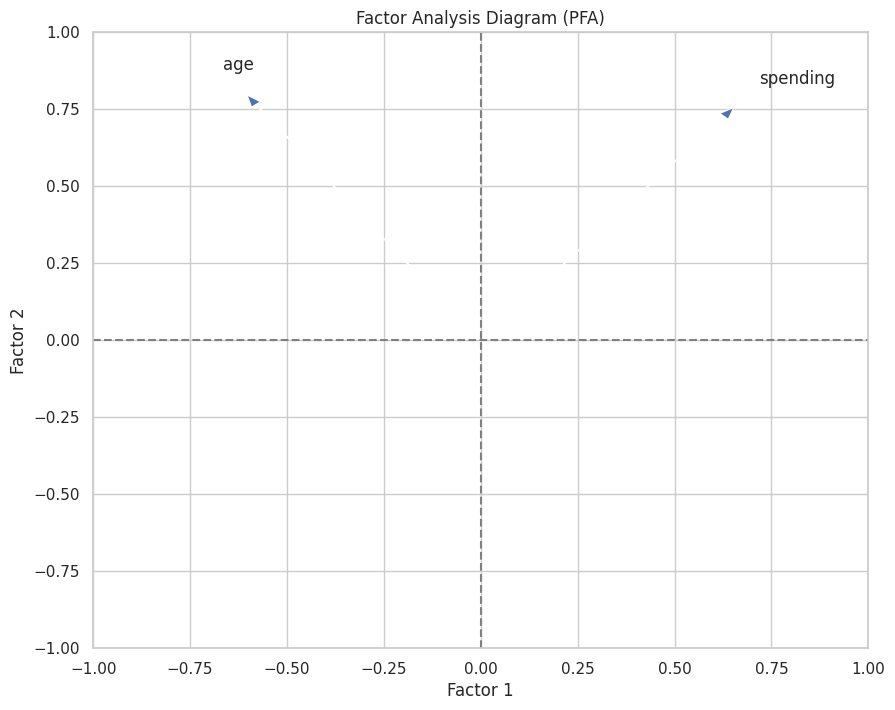

In [ ]:


# Mengambil nilai loading dari hasil PFA
loadings = fa_pfa.loadings_

# Membuat figure
plt.figure(figsize=(10, 8))

# Menggambar garis sumbu X dan Y
plt.axhline(y=0, color="gray", linestyle="--")
plt.axvline(x=0, color="gray", linestyle="--")

# Menggambar panah untuk setiap variabel
for i, variable in enumerate(data_fa.columns):

    x = loadings[i, 0]
    y = loadings[i, 1]

    plt.arrow(
        0, 0, x, y,
        head_width=0.03,
        head_length=0.04,
        length_includes_head=True
    )

    plt.text(
        x * 1.1,
        y * 1.1,
        variable,
        fontsize=12
    )

# Memberikan batas sumbu
plt.xlim(-1, 1)
plt.ylim(-1, 1)

# Judul dan label
plt.title("Factor Analysis Diagram (PFA)")
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")

plt.grid(True)
plt.show()

Bagian Clustering

In [ ]:
# Menampilkan dataset customer
data.head()

# Menghapus customer_id karena hanya merupakan identitas
data_cluster = data.drop(columns=["customer_id"])

# Menampilkan variabel yang digunakan dalam clustering
data_cluster.head()

,age,spending
0,51,4339
1,48,4700
2,10,1352
3,37,2457
4,42,1266


Feature Scalling

In [ ]:
# Membuat objek MinMaxScaler
scaler = MinMaxScaler()

# Melakukan normalisasi data
data_scaled = scaler.fit_transform(data_cluster)

# Mengubah hasil scaling menjadi DataFrame
data_scaled = pd.DataFrame(
    data_scaled,
    columns=data_cluster.columns
)

# Menampilkan data hasil scaling
data_scaled.head()

,age,spending
0,0.611940,0.249039
1,0.567164,0.269758
2,0.000000,0.077599
3,0.402985,0.141020
4,0.477612,0.072663


Visualisasi Sebelum Clustering

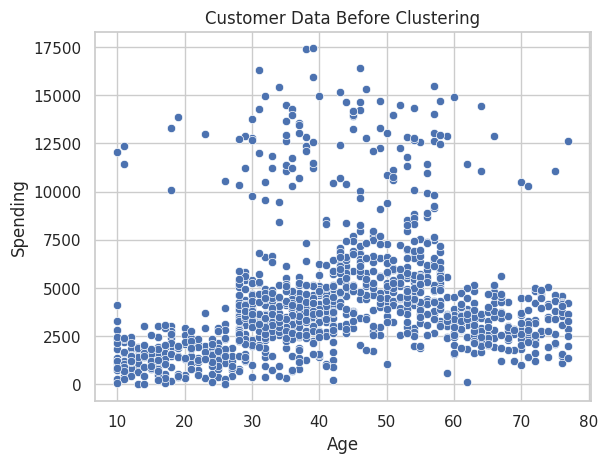

In [ ]:
# Membuat scatter plot data customer
sns.scatterplot(
    data=data_cluster,
    x="age",
    y="spending"
)

plt.title("Customer Data Before Clustering")
plt.xlabel("Age")
plt.ylabel("Spending")

plt.show()

Agglomerative Clustering SIngle Linked

In [ ]:
# Membentuk model Agglomerative Clustering
agg_clus_single = AgglomerativeClustering(
    n_clusters=5,
    linkage="single"
)

# Melakukan clustering
agg_clus_single.fit(data_scaled)

# Menampilkan label cluster
agg_clus_single.labels_

# Menambahkan label single linkage
data_cluster["label_single"] = agg_clus_single.labels_

# Menampilkan hasil clustering
data_cluster.head()

,age,spending,label_single
0,51,4339,0
1,48,4700,0
2,10,1352,0
3,37,2457,0
4,42,1266,0


Visualisasi hasil clustering single linkage

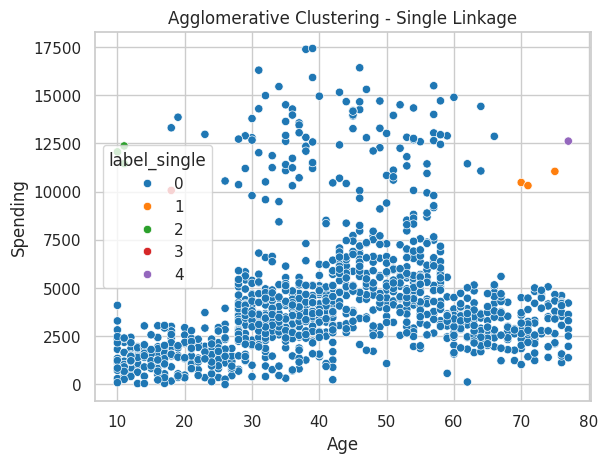

In [ ]:
# Visualisasi hasil clustering single linkage
sns.scatterplot(
    data=data_cluster,
    x="age",
    y="spending",
    hue="label_single",
    palette="tab10"
)

plt.title("Agglomerative Clustering - Single Linkage")
plt.xlabel("Age")
plt.ylabel("Spending")

plt.show()

Agglomerative Clustering Ward

In [ ]:
# Membentuk model Agglomerative Clustering Ward
agg_clus_ward = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

# Melakukan clustering
agg_clus_ward.fit(data_scaled)

# Menampilkan label cluster
agg_clus_ward.labels_

# Menambahkan label hasil Ward
data_cluster["label_ward"] = agg_clus_ward.labels_

# Menampilkan hasil clustering
data_cluster.head()

,age,spending,label_single,label_ward
0,51,4339,0,1
1,48,4700,0,4
2,10,1352,0,3
3,37,2457,0,0
4,42,1266,0,0


Visualisasi hasil clustering ward

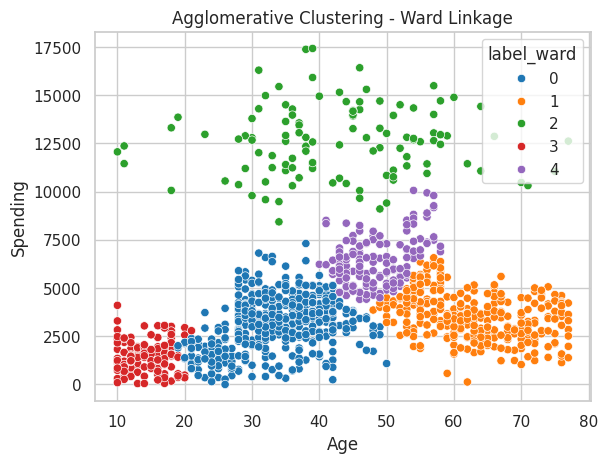

In [ ]:
# Membuat scatter plot hasil clustering Ward
sns.scatterplot(
    data=data_cluster,
    x="age",
    y="spending",
    hue="label_ward",
    palette="tab10"
)

plt.title("Agglomerative Clustering - Ward Linkage")
plt.xlabel("Age")
plt.ylabel("Spending")

plt.show()

Dendogram

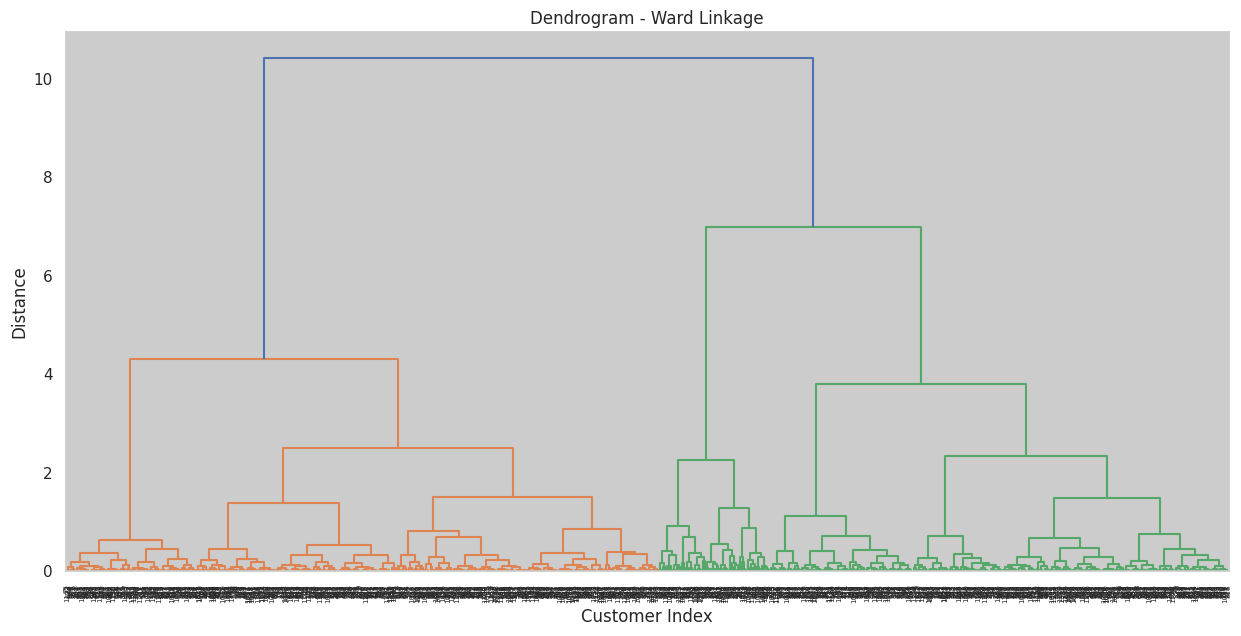

In [ ]:
# Membentuk linkage matrix menggunakan metode Ward
linkage_matrix = linkage(
    data_scaled,
    method="ward"
)

# Membuat ukuran grafik
plt.figure(figsize=(15, 7))

# Membuat dendrogram
dendrogram(linkage_matrix)

plt.title("Dendrogram - Ward Linkage")
plt.xlabel("Customer Index")
plt.ylabel("Distance")

plt.show()

Menghitung jumlah customer dalam setiap cluster

In [ ]:
# Menghitung jumlah customer dalam setiap cluster
cluster_count = data_cluster["label_ward"].value_counts()

# Mengurutkan label cluster
cluster_count = cluster_count.sort_index()

print("Jumlah Customer Setiap Cluster:")
display(cluster_count)

Jumlah Customer Setiap Cluster:


,count
label_ward,
0,468
1,319
2,112
3,131
4,145


Profil cluster

In [ ]:
# Menghitung rata-rata age dan spending
cluster_profile = data_cluster.groupby(
    "label_ward"
)[["age", "spending"]].mean()

# Menampilkan profil cluster
print("Profil Cluster Ward:")
display(cluster_profile)

Profil Cluster Ward:


,age,spending
label_ward,,
0,33.525641,3183.658120
1,62.858934,3564.905956
2,42.946429,12602.178571
3,14.419847,1484.099237
4,48.468966,6414.813793


visualisasi rata-rata spending

/tmp/ipykernel_2093/1637574969.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


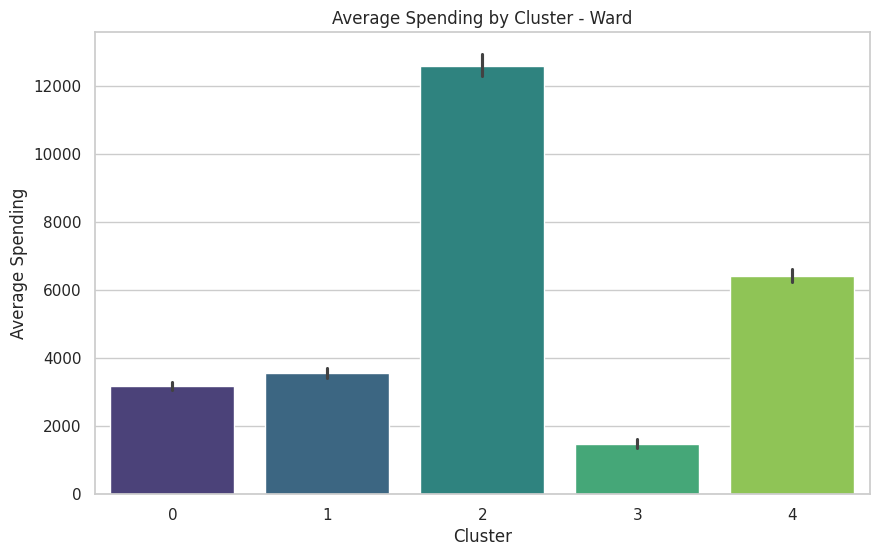

In [ ]:
# Membuat visualisasi rata-rata spending setiap cluster
plt.figure(figsize=(10, 6))

sns.barplot(
    data=data_cluster,
    x="label_ward",
    y="spending",
    estimator="mean",
    palette="viridis"
)

plt.title("Average Spending by Cluster - Ward")
plt.xlabel("Cluster")
plt.ylabel("Average Spending")

plt.show()

visualisasi rata-rata age

/tmp/ipykernel_2093/1185843236.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


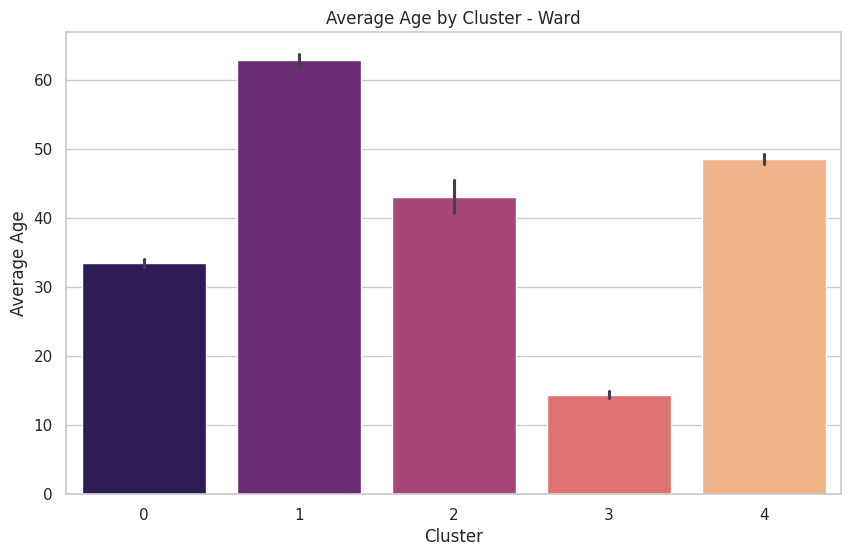

In [ ]:
# Membuat visualisasi rata-rata age setiap cluster
plt.figure(figsize=(10, 6))

sns.barplot(
    data=data_cluster,
    x="label_ward",
    y="age",
    estimator="mean",
    palette="magma"
)

plt.title("Average Age by Cluster - Ward")
plt.xlabel("Cluster")
plt.ylabel("Average Age")

plt.show()